Данные о банкротствах, опубликованные в Тайваньском экономическом журнале за 1999-2009 годы.
Цель: построить модель классификации для прогноза, какие факторы больше всего влияют на банкротство компаний.

Практическая польза для банка: данная модель будет являться эффективным инструментом для оценки состояния юридических лиц и оценки уровня рисков при работе с этими клиентами

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
from sklearn.metrics import roc_curve

In [4]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

Этап 1: загрузка и первичный осмотр данных

In [5]:
data = pd.read_csv('bank.csv')
data.head(10)

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,1.256969e-04,0.0,0.458143,0.000725,0.000000,0.147950,0.147950,0.147950,0.169141,0.311664,0.017560,0.095921,0.138736,0.022102,0.848195,0.688979,0.688979,0.217535,4.980000e+09,0.000327,0.263100,0.363725,0.002259,0.001208,0.629951,0.021266,0.207576,0.792424,0.005024,0.390284,0.006479,0.095885,0.137757,0.398036,0.086957,0.001814,0.003487,1.820926e-04,1.165007e-04,0.032903,0.034164,0.392913,0.037135,0.672775,0.166673,0.190643,0.004094,0.001997,1.473360e-04,0.147308,0.334015,0.276920,0.001036,0.676269,0.721275,0.339077,0.025592,0.903225,0.002022,0.064856,7.010000e+08,6.550000e+09,0.593831,4.580000e+08,0.671568,0.424206,0.676269,0.339077,0.126549,0.637555,0.458609,0.520382,0.312905,0.118250,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,2.897851e-04,0.0,0.461867,0.000647,0.000000,0.182251,0.182251,0.182251,0.208944,0.318137,0.021144,0.093722,0.169918,0.022080,0.848088,0.689693,0.689702,0.217620,6.110000e+09,0.000443,0.264516,0.376709,0.006016,0.004039,0.635172,0.012502,0.171176,0.828824,0.005059,0.376760,0.005835,0.093743,0.168962,0.397725,0.064468,0.001286,0.004917,9.360000e+09,7.190000e+08,0.025

In [6]:
data.shape

(6819, 96)

In [7]:
print(data.dtypes.value_counts())
# Все данные приведены к виду для расчетов

float64    93
int64       3
Name: count, dtype: int64


Этап 2: Разведочный анализ данных (Exploratory Data Analysis, EDA)

In [8]:
if data.isna().sum().sum() == 0:
    print('Пропуски в данных отсутствуют')
else:
    print(data.isna().sum()[data.isna().sum() > 0])

Пропуски в данных отсутствуют


In [9]:
# Удаление столбцов, где все значения: константа
columns_to_drop = data.columns[data.nunique() == 1]
data = data.drop(columns=columns_to_drop)
data.shape

(6819, 95)

Удален 1 столбец

In [10]:
data.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6.819000e+03,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,0.781381,1.995347e+09,1.950427e+09,0.467431,1.644801e+07,0.115001,0.190661,0.190633,

1. 6819 компании рассматривались в исследовании
2. Переменная "Банкрот?" является бинарной (1 - компания обанкротилась, 0 - компания не обанкротилась
3. Все остальные переменные непрерывные, находятся в диапазоне от 0 до 1.

In [11]:
count_Bankrupt = (data['Bankrupt?'] == 1).sum()
count_Bankrupt

np.int64(220)

220 компаний обанкротились

In [12]:
# Рассчет корреляции
matrix = data.corr()
matrix 

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
Bankrupt?,1.000000,-0.260807,-0.282941,-0.273051,-0.100043,-0.099445,-0.000230,-0.008517,-0.008857,-0.016593,-0.008395,-0.006083,-0.024232,-0.072356,-0.023063,-0.109706,-0.165399,-0.165465,-0.164784,-0.219560,-0.077516,-0.004692,-0.142051,-0.201395,-0.000458,-0.015168,-0.037783,-0.036820,-0.009401,-0.044431,0.065329,-0.016858,-0.051345,-0.002211,0.025058,-0.002681,0.012314,0.250161,-0.250161,0.016920,0.176543,0.070455,-0.141111,-0.207857,0.075278,-0.067915,-0.004754,-0.006556,-0.001376,0.072818,0.021089,0.039718,-0.092842,0.002829,-0.193083,-0.086382,-0.044823,-0.100130,-0.003823,0.077921,0.194494,-0.077082,-0.001906,0.000822,-0.020809,-0.147221,0.153828,0.000778,-0.217779,-0.007137,0.139049,0.011929,0.025814,-0.002894,-0.018035,0.000479,0.066328,-0.020809,0.153828,0.139014,-0.070456,-0.043125,-0.115383,-0.058563,0.171306,0.139212,-0.315457,0.035104,-0.005547,-0.100044,-0.180987,0.166812,0.010508,-0.005509,-0.083048
ROA(C) before interest and depreciation before interest,-0.260807,1.000000,0.940124,0.986849,0.334719,0.332755,0.035725,0.053419,0.049222,0.020501,0.051328,0.066869,0.106461,0.323482,0.048882,0.250761,0.505580,0.505407,0.505281,0.775006,0.379839,-0.015932,0.687201,0.750564,0.000591,0.036511,0.115083,0.115040,0.025234,0.019635,-0.021930,0.079906,0.296158,0.013196,-0.026336,0.003988,-0.022208,-0.261427,0.261427,0.0029

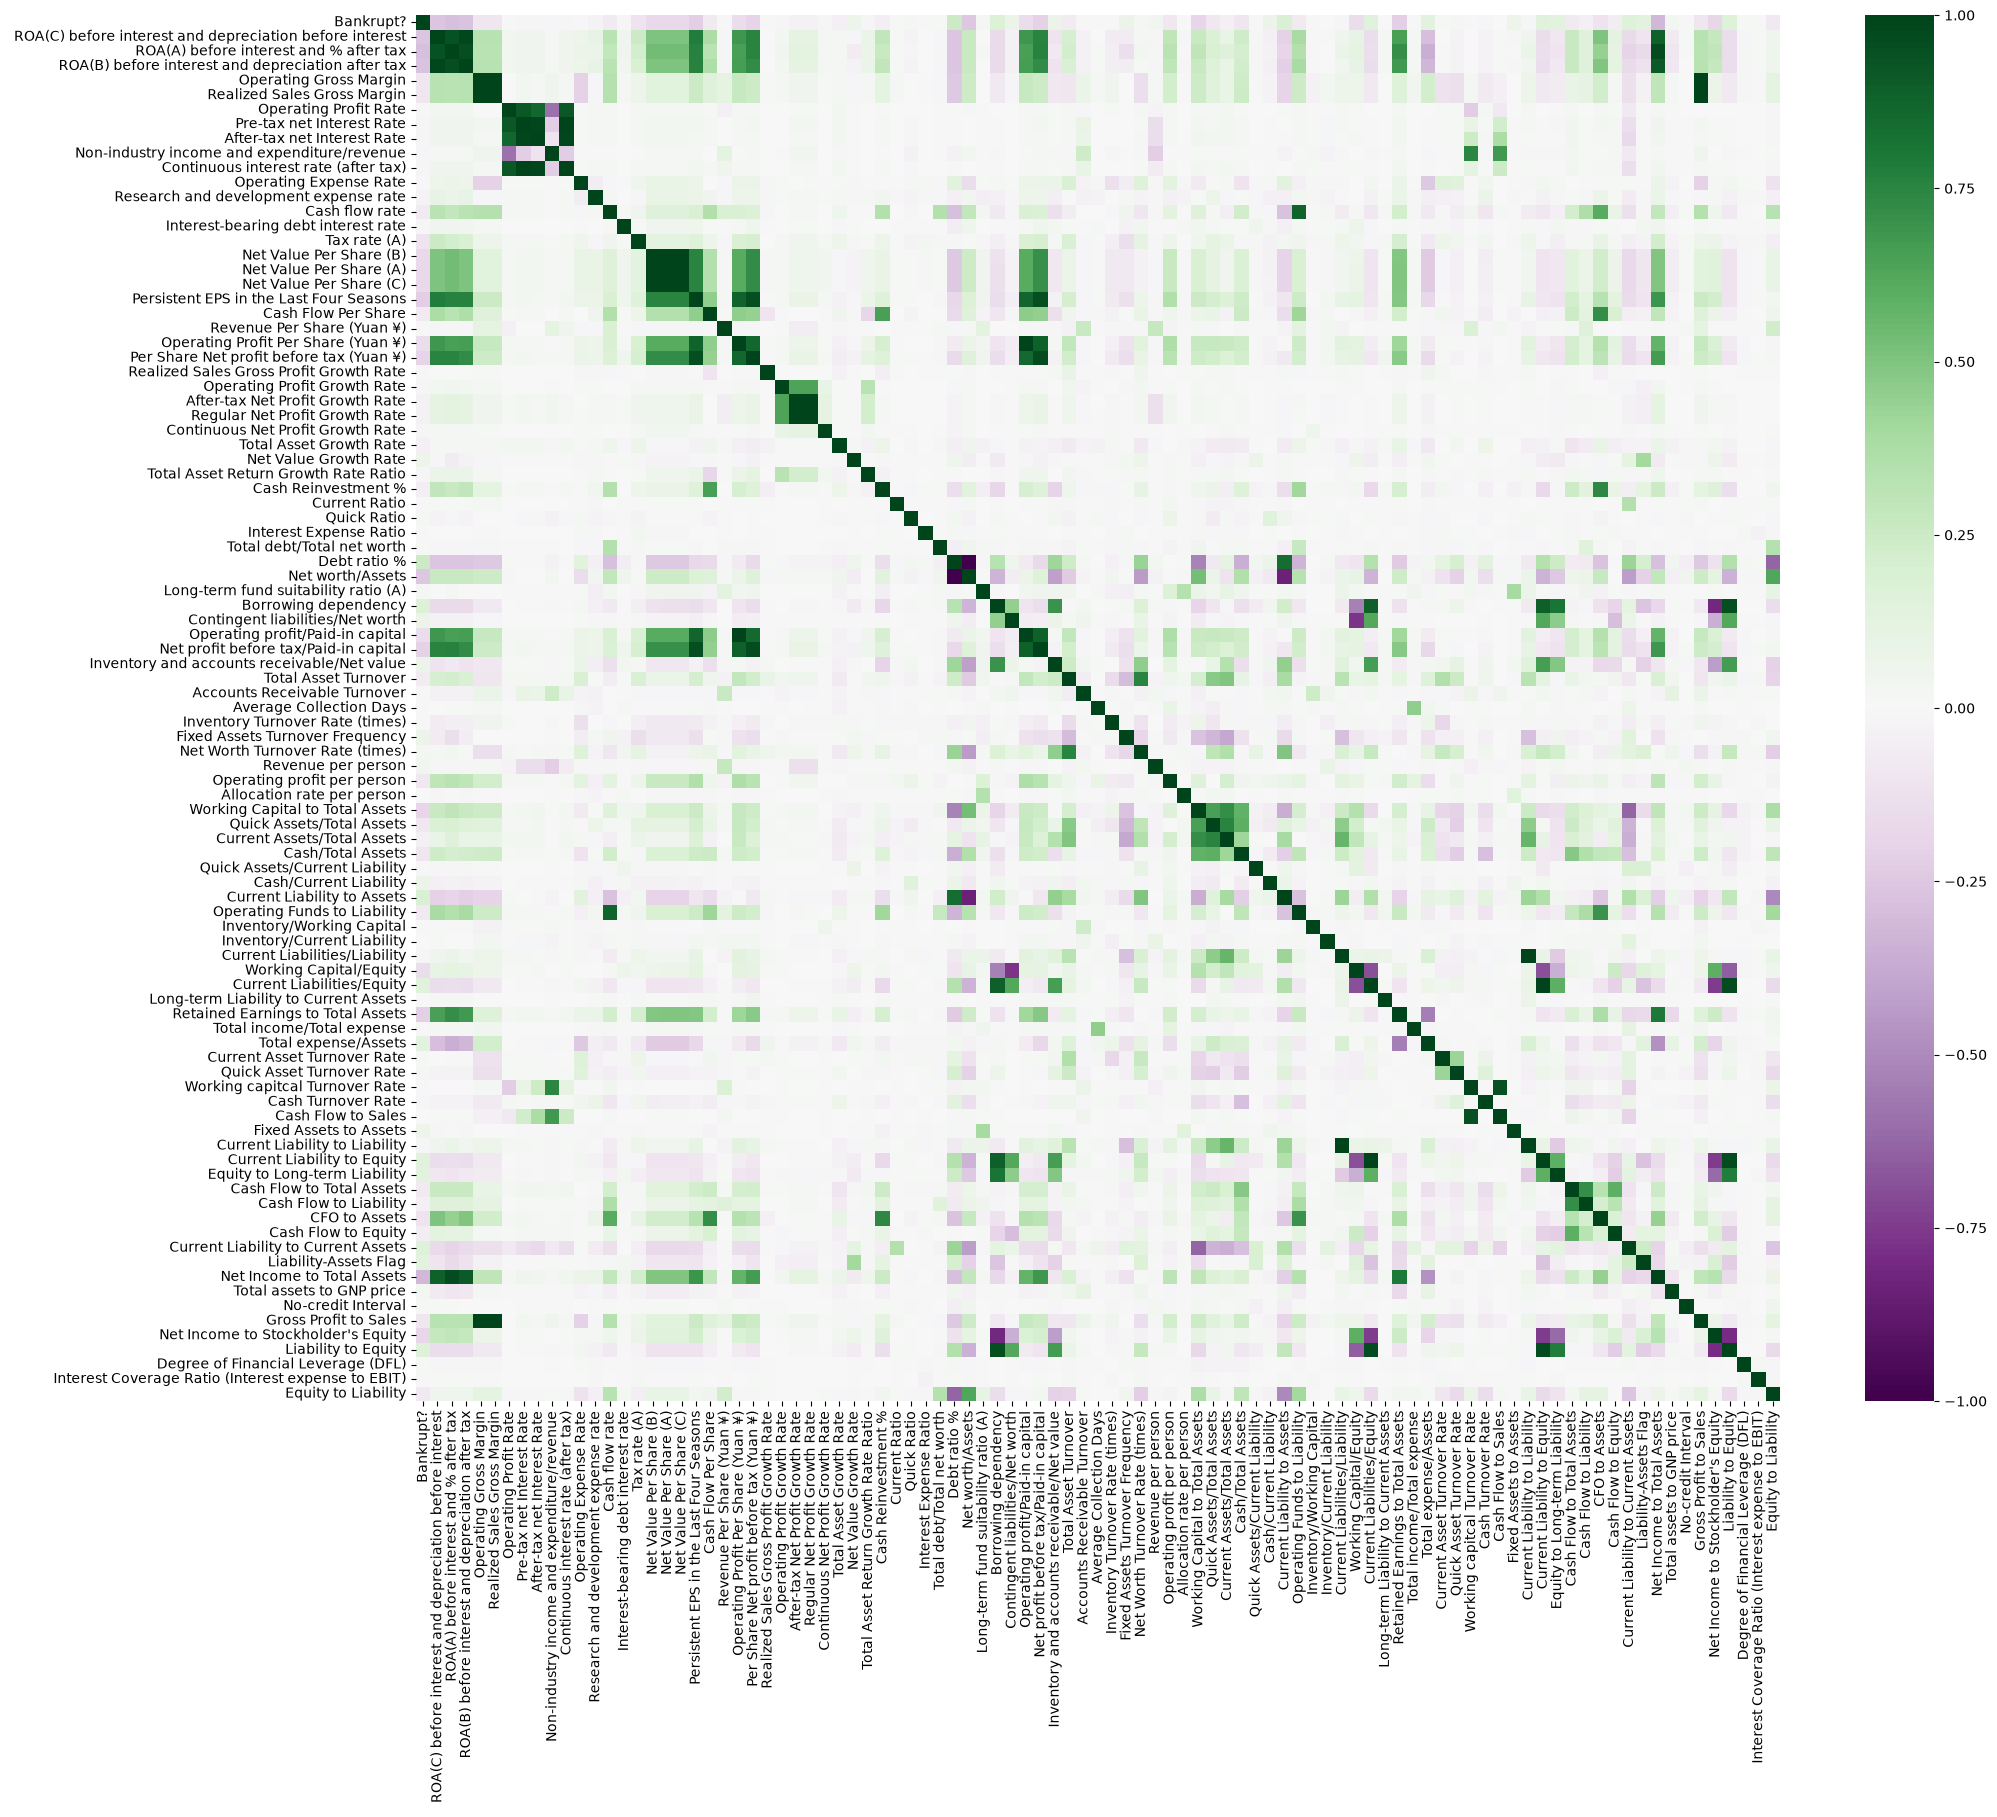

In [13]:
plt.figure(figsize=(22, 18))
sns.heatmap(matrix, cmap='PRGn')
plt.show()

In [14]:
# Анализ мультиколлинеарности переменных
# Цель: сделать анализ корреляции и выявить признаки, которые сильно коррелируют между собой

target_variable = 'Bankrupt?' # Целевая переменная

#Абсолютная корреляция
limit = 0.90

# 1. Корреляция с target
corr_target = data.corr()[target_variable].abs()

# 2. Корреляция без target
features_matrix = data.drop(columns=[target_variable]).corr().abs()

# 3. Только верхний треугольник мартицы без диагонали (остальное заполняем NaN)
upper_tri = features_matrix.where(np.triu(np.ones(features_matrix.shape), k=1).astype(bool))

# 4. Изменяем форму матрицы в плоский вид, убираем NaN
high_corr_pairs = (
   upper_tri.stack()
    .loc[lambda s: s > limit] # фильтрует полученный список
    .sort_values(ascending=False)   
)

columns_to_drop = set() # колонка на удаление

# Проходим по найденным парам
for (col1, col2), corr in high_corr_pairs.items():
        if col1 in columns_to_drop or col2 in columns_to_drop:
            continue

        print(f'{col1} <-> {col2}: {corr:.3f}')
            
        if  corr_target[col1] < corr_target[col2]:
            columns_to_drop.add(col1)                   
        else:
            columns_to_drop.add(col2)
            
cleaned_data = data.drop(columns=columns_to_drop)

print(f'Всего удалено колонок: {len(columns_to_drop)}')

print(f'Размер нового набора данных: {cleaned_data.shape}')

print(f'Список удаленных колонок: {list(columns_to_drop)}')

 Current Liabilities/Equity <->  Current Liability to Equity: 1.000
 Current Liabilities/Liability <->  Current Liability to Liability: 1.000
 Debt ratio % <->  Net worth/Assets: 1.000
 Operating Gross Margin <->  Gross Profit to Sales: 1.000
 Net Value Per Share (A) <->  Net Value Per Share (C): 1.000
 Realized Sales Gross Margin <->  Gross Profit to Sales: 1.000
 Net Value Per Share (B) <->  Net Value Per Share (A): 0.999
 Operating Profit Per Share (Yuan ¥) <->  Operating profit/Paid-in capital: 0.999
 After-tax Net Profit Growth Rate <->  Regular Net Profit Growth Rate: 0.996
 Pre-tax net Interest Rate <->  Continuous interest rate (after tax): 0.994
 ROA(C) before interest and depreciation before interest <->  ROA(B) before interest and depreciation after tax: 0.987
 Pre-tax net Interest Rate <->  After-tax net Interest Rate: 0.986
 Current Liabilities/Equity <->  Liability to Equity: 0.964
 Per Share Net profit before tax (Yuan ¥) <->  Net profit before tax/Paid-in capital: 0.963

In [15]:
matrix2 = cleaned_data.corr()
matrix2

,Bankrupt?,Operating Profit Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (A),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Fixed Assets to Assets,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Equity to Liability
Bankrupt?,1.000000,-0.000230,-0.008857,-0.016593,-0.006083,-0.024232,-0.072356,-0.023063,-0.109706,-0.165465,-0.219560,-0.077516,-0.004692,-0.142051,-0.000458,-0.015168,-0.037783,-0.009401,-0.044431,0.065329,-0.016858,-0.051345,-0.002211,0.025058,-0.002681,0.012314,-0.250161,0.016920,0.176543,0.070455,0.075278,-0.067915,-0.004754,-0.006556,-0.001376,0.072818,0.021089,0.039718,-0.092842,0.002829,-0.193083,-0.086382,-0.044823,-0.100130,-0.003823,0.077921,0.194494,-0.077082,-0.001906,0.000822,-0.020809,-0.147221,0.000778,-0.217779,-0.007137,0.139049,0.011929,0.025814,-0.002894,-0.018035,0.066328,0.139014,-0.070456,-0.043125,-0.115383,-0.058563,0.171306,0.139212,-0.315457,0.035104,-0.005547,-0.100044,-0.180987,0.010508,-0.005509,-0.083048
Operating Profit Rate,-0.000230,1.000000,0.862191,-0.592006,0.013246,0.016387,0.023051,0.002784,0.019936,0.019218,0.020420,0.014244,-0.044460,0.022397,0.000831,0.004952,0.011328,0.001318,0.034465,-0.000207,0.003677,0.014955,0.000833,0.000323,0.001156,-0.001507,-0.010397,-0.000833,0.001092,0.000247,0.011993,0.029456,-0.023171,0.001001,0.009576,0.005232,0.016064,-0.027450,0.018248,0.000726,0.025599,0.026100,0.033821,0.010465,0.000365,0.000301,0.011340,0.020308,-0.001026,-0.001748,0.020520,0.010600,0.001967,0.021280,0.002047,0.005401,0.008117,0.012696,-0.229568,0.016485,0.000106,-0.000654,0.020918,0.004669,0.026682,0.014088,-0.079679,-0.000295,0.028482,-0.003338,0.000199,0.005746,0.006216,0.000935,0.000393,-0.017071
After-tax net Interest Rate,-0.008857,0.862191,1.000000,-0.115211,0.013982,0.016521,0.022813,0.003824,0.021164,0.031347,0.030768,0.016140,0.005594,0.024137,0.001226,0.002962,0.031223,0.002565,0.037066,-0.000858,0.004379,0.016692,0.002685,-0.015369,0.001612,-0.001379,0.006174,-0.001227,-0.004395,0.002117,0.008993,0.029504,0.079920,0.002032,0.005957,0.004241,0.015736,-0.146671,0.018334,0.000702,0.040405,0.031453,0.037836,0.017118,0.000343,-0.000827,-0.002805,0.020877

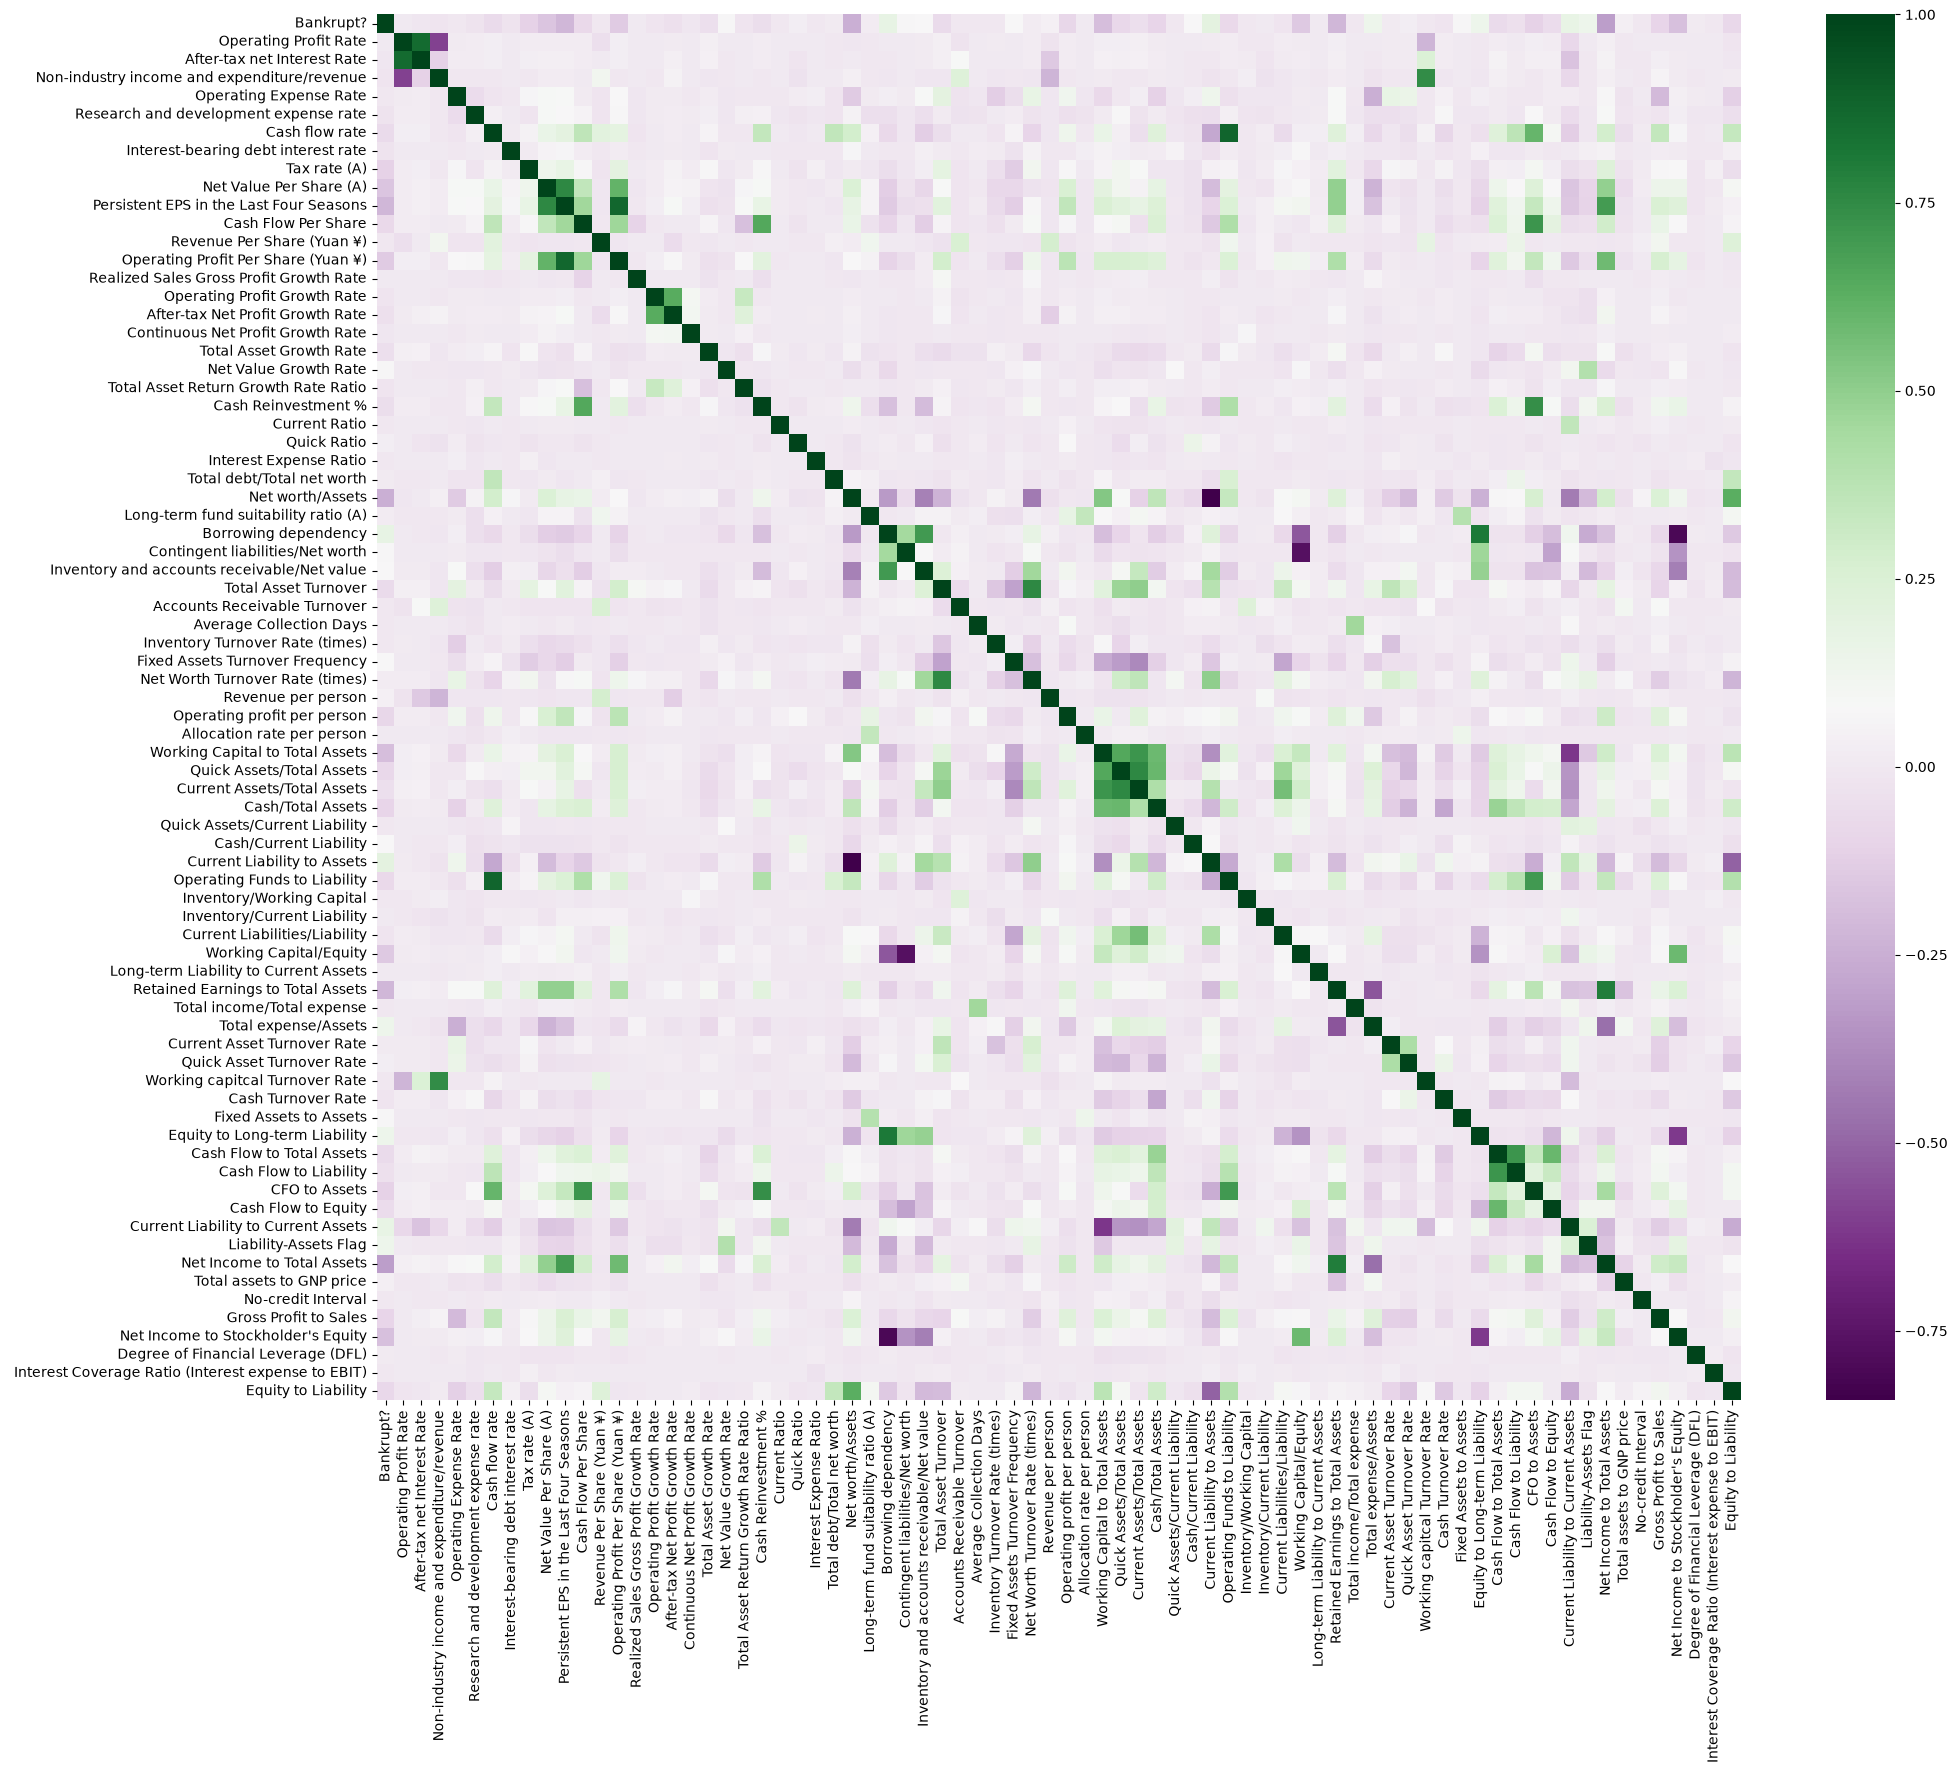

In [16]:
plt.figure(figsize=(22, 18))
sns.heatmap(matrix2, cmap='PRGn')
plt.show()

Визуализация данных

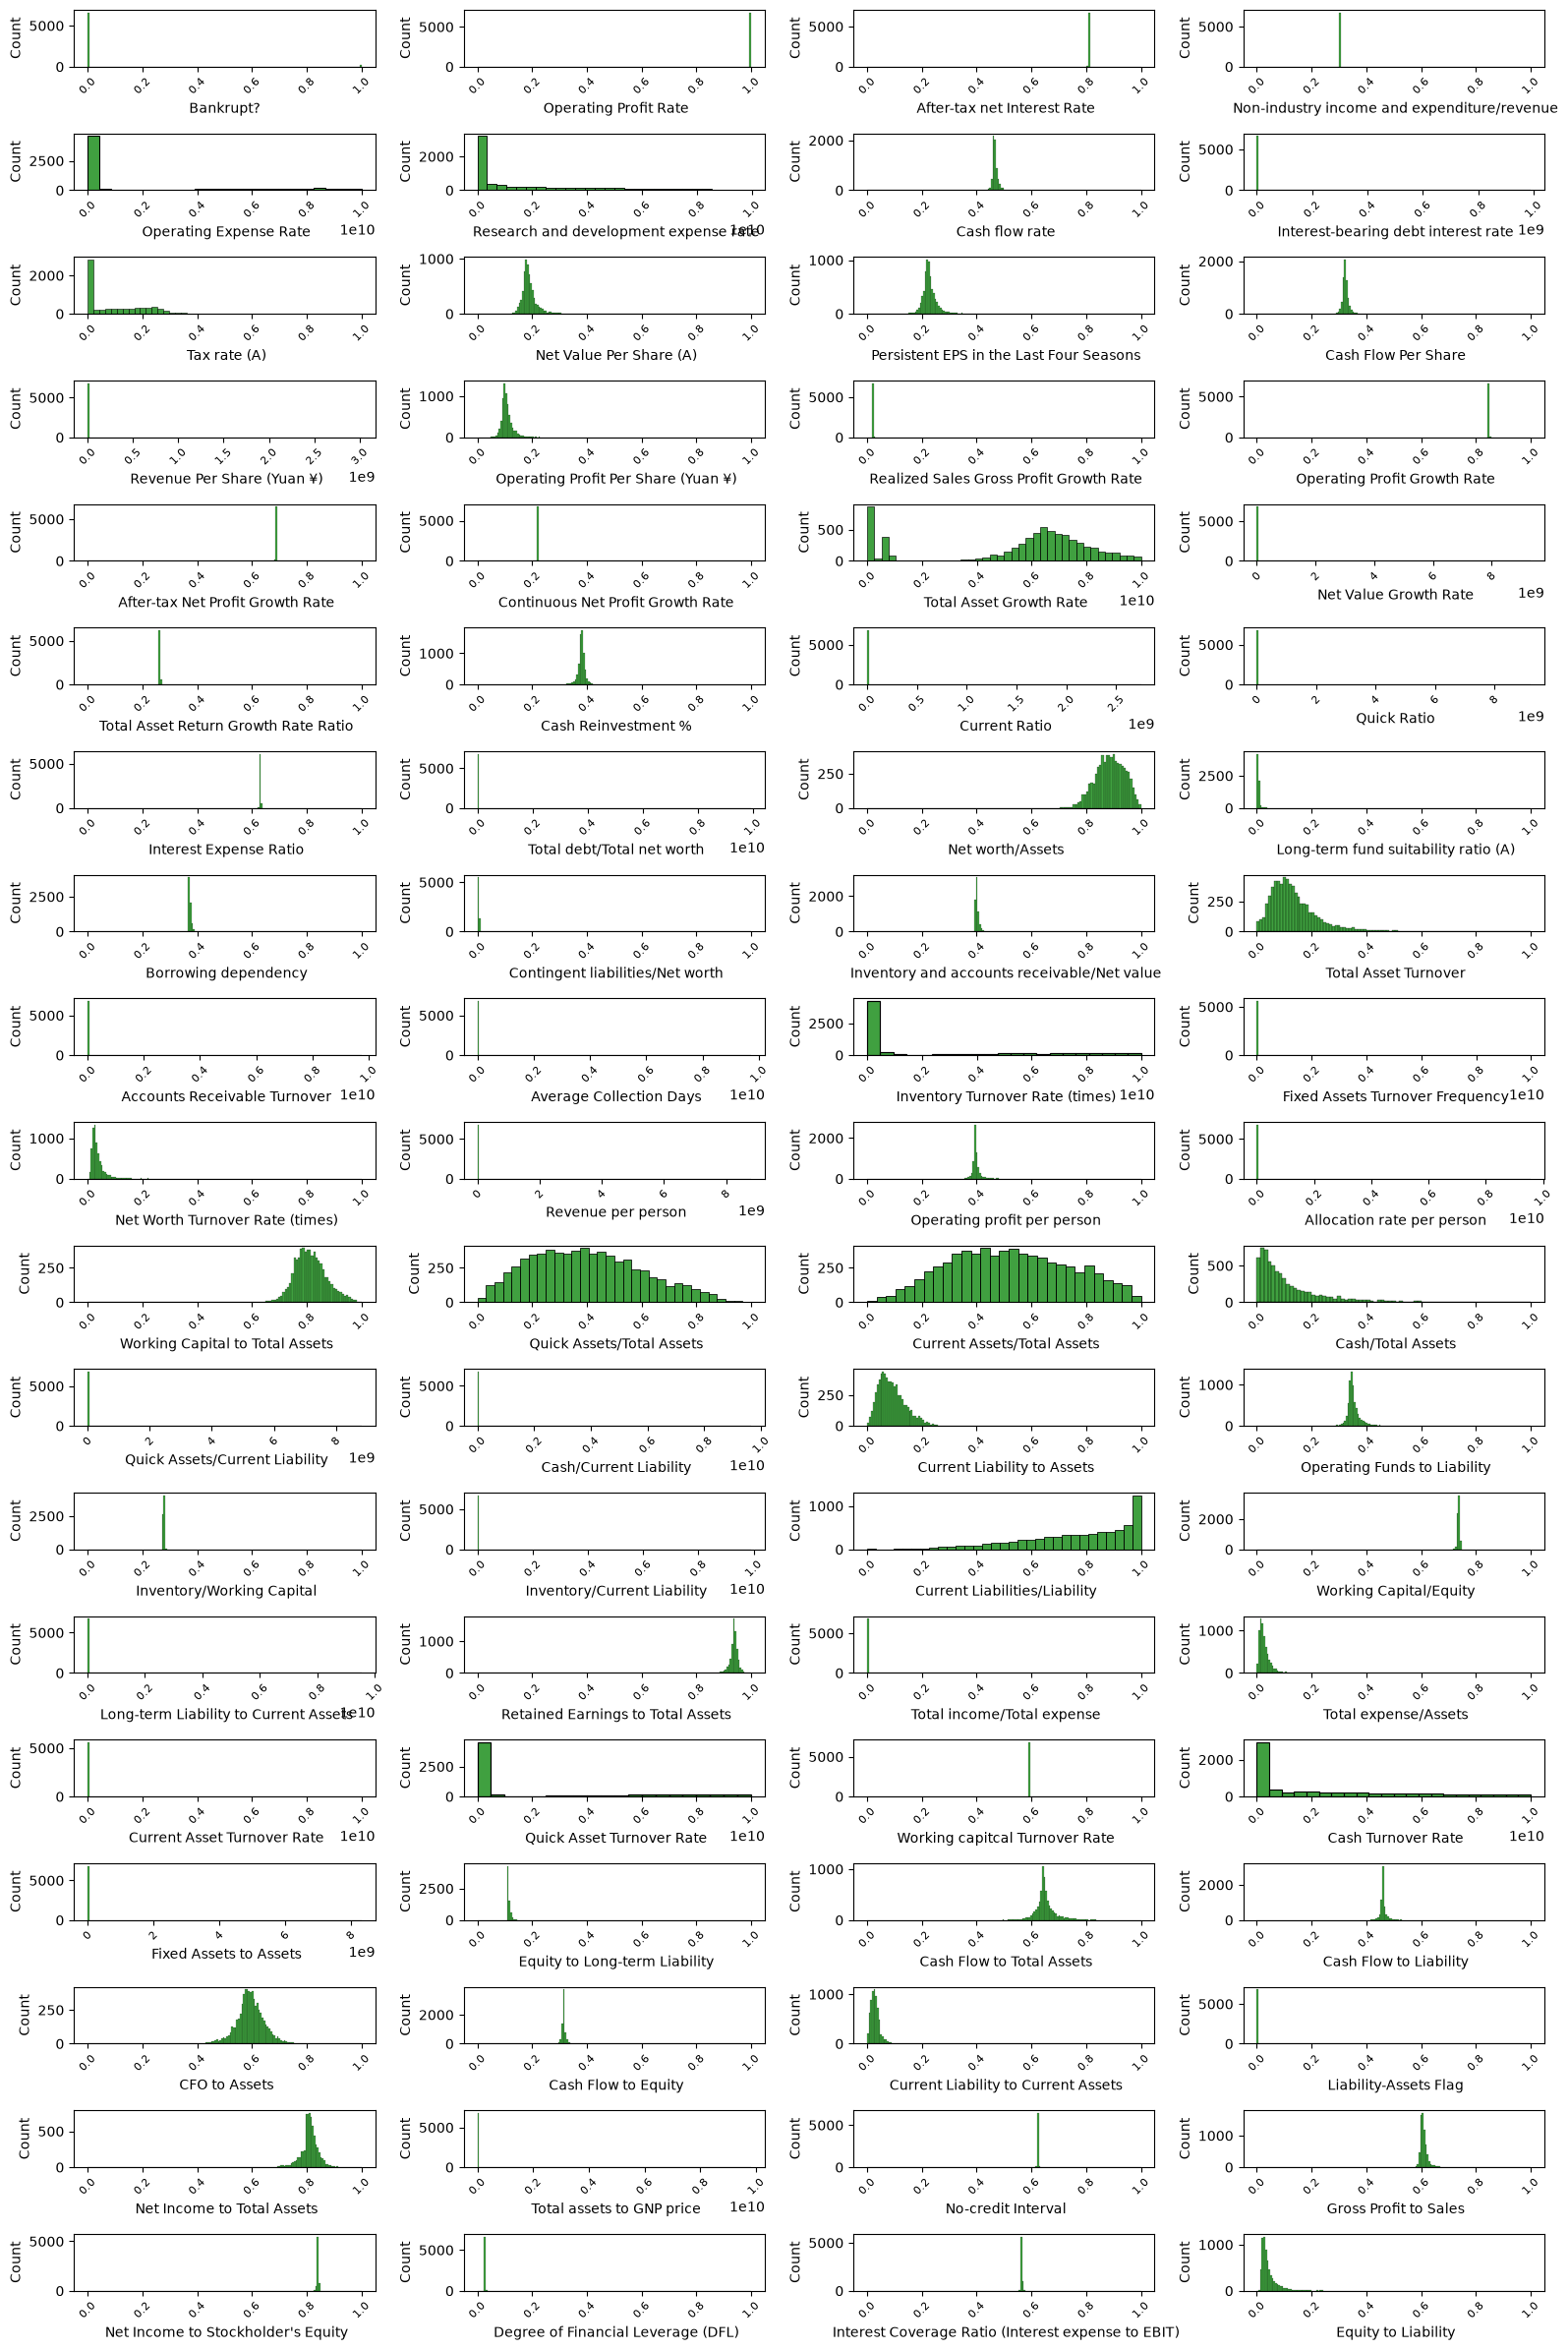

In [17]:
fig, axes = plt.subplots(19, 4, figsize=(16, 24))
axes = axes.flatten()

for i, col in enumerate(cleaned_data):
    sns.histplot(data=cleaned_data, x=col, ax=axes[i], color='green')
    axes[i].tick_params(axis='x', labelsize=8, rotation=45)

# Скрываем лишние пустые окна
for j in range(len(cleaned_data), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

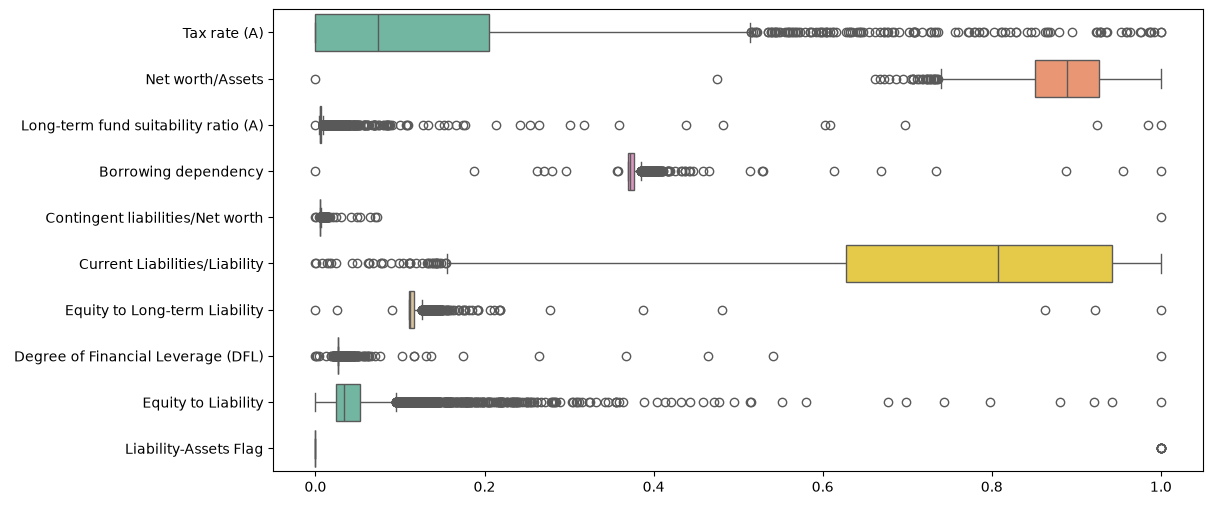

In [18]:
debt_load = [' Tax rate (A)',' Net worth/Assets', ' Long-term fund suitability ratio (A)', ' Borrowing dependency', \
' Contingent liabilities/Net worth', ' Current Liabilities/Liability',' Equity to Long-term Liability', \
' Degree of Financial Leverage (DFL)', ' Equity to Liability', \
' Liability-Assets Flag']
plt.figure(figsize=(12, 6))
sns.boxplot(data=cleaned_data[debt_load], orient='h', palette='Set2')
plt.show()

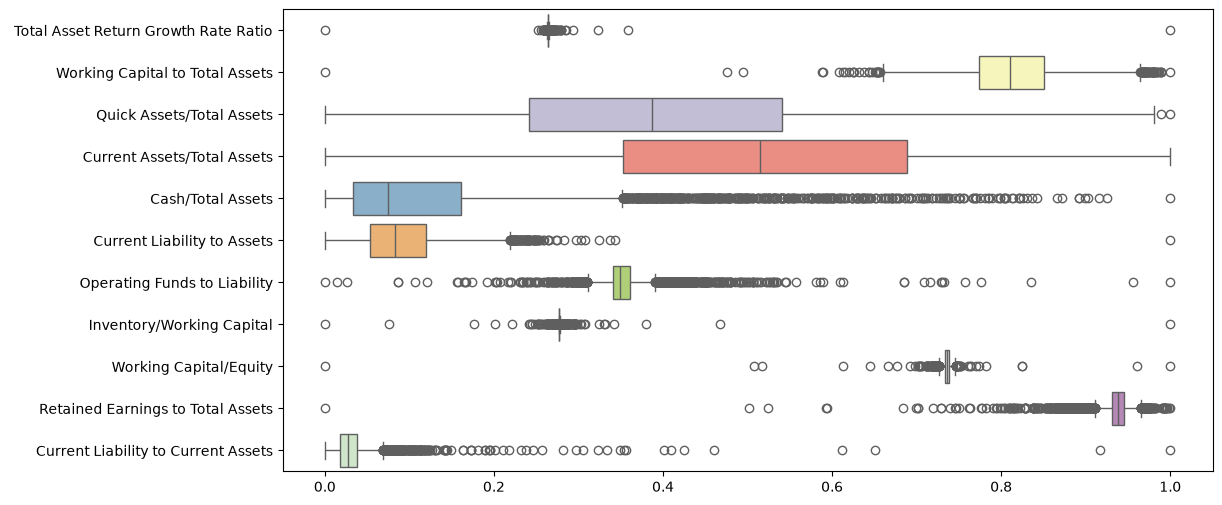

In [19]:
liquidity = [' Total Asset Return Growth Rate Ratio', ' Working Capital to Total Assets',' Quick Assets/Total Assets', \
' Current Assets/Total Assets', ' Cash/Total Assets',' Current Liability to Assets', ' Operating Funds to Liability', \
' Inventory/Working Capital', ' Working Capital/Equity', ' Retained Earnings to Total Assets', ' Current Liability to Current Assets']
plt.figure(figsize=(12, 6))
sns.boxplot(data=cleaned_data[liquidity], orient='h', palette='Set3')
plt.show()

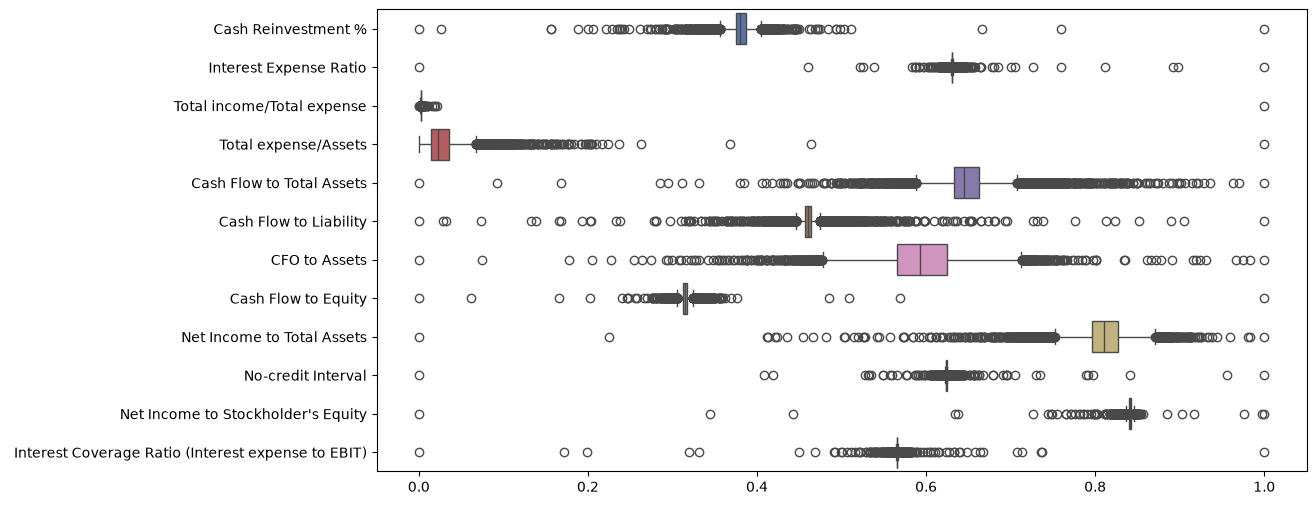

In [20]:
cash_flows = [' Cash Reinvestment %', ' Interest Expense Ratio', ' Total income/Total expense',' Total expense/Assets', \
' Cash Flow to Total Assets', ' Cash Flow to Liability', ' CFO to Assets', ' Cash Flow to Equity', ' Net Income to Total Assets', \
' No-credit Interval', ' Net Income to Stockholder\'s Equity',' Interest Coverage Ratio (Interest expense to EBIT)']
plt.figure(figsize=(12, 6))
sns.boxplot(data=cleaned_data[cash_flows], orient='h', palette='deep')
plt.show()

Визуальный анализ показал графиков Boxplot показал, что для большинства исследуемых переменных арактерно наличие значительное количество экстремальных значений

3 Этап: разбивка данных, применение CatBoost и проверка качества модели

In [21]:
# Выделение признаков
X = cleaned_data.drop(columns =['Bankrupt?'])
y = cleaned_data['Bankrupt?']

In [22]:
# X_val, y_val - (Валидационная выборка)
# Разделение Train / Valid / Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [23]:
model = CatBoostClassifier(
    iterations = 1000,
    learning_rate = 0.05,
    depth = 6,
    auto_class_weights='Balanced', # от дисбаланса
    random_state = 42, 
    verbose = 100)

model.fit(
    X_tr, y_tr,
    eval_set=(X_val, y_val),
    early_stopping_rounds=50,
    verbose=100
)

0:	learn: 0.6423016	test: 0.6435444	best: 0.6435444 (0)	total: 65.7ms	remaining: 1m 5s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.3490831953
bestIteration = 46

Shrink model to first 47 iterations.


CatBoostClassifier(auto_class_weights='Balanced', depth=6, iterations=1000, learning_rate=0.05, random_state=42, verbose=100)

In [24]:
y_predict = model.predict(X_test)

In [25]:
importance = model.get_feature_importance()
feature_names = X.columns

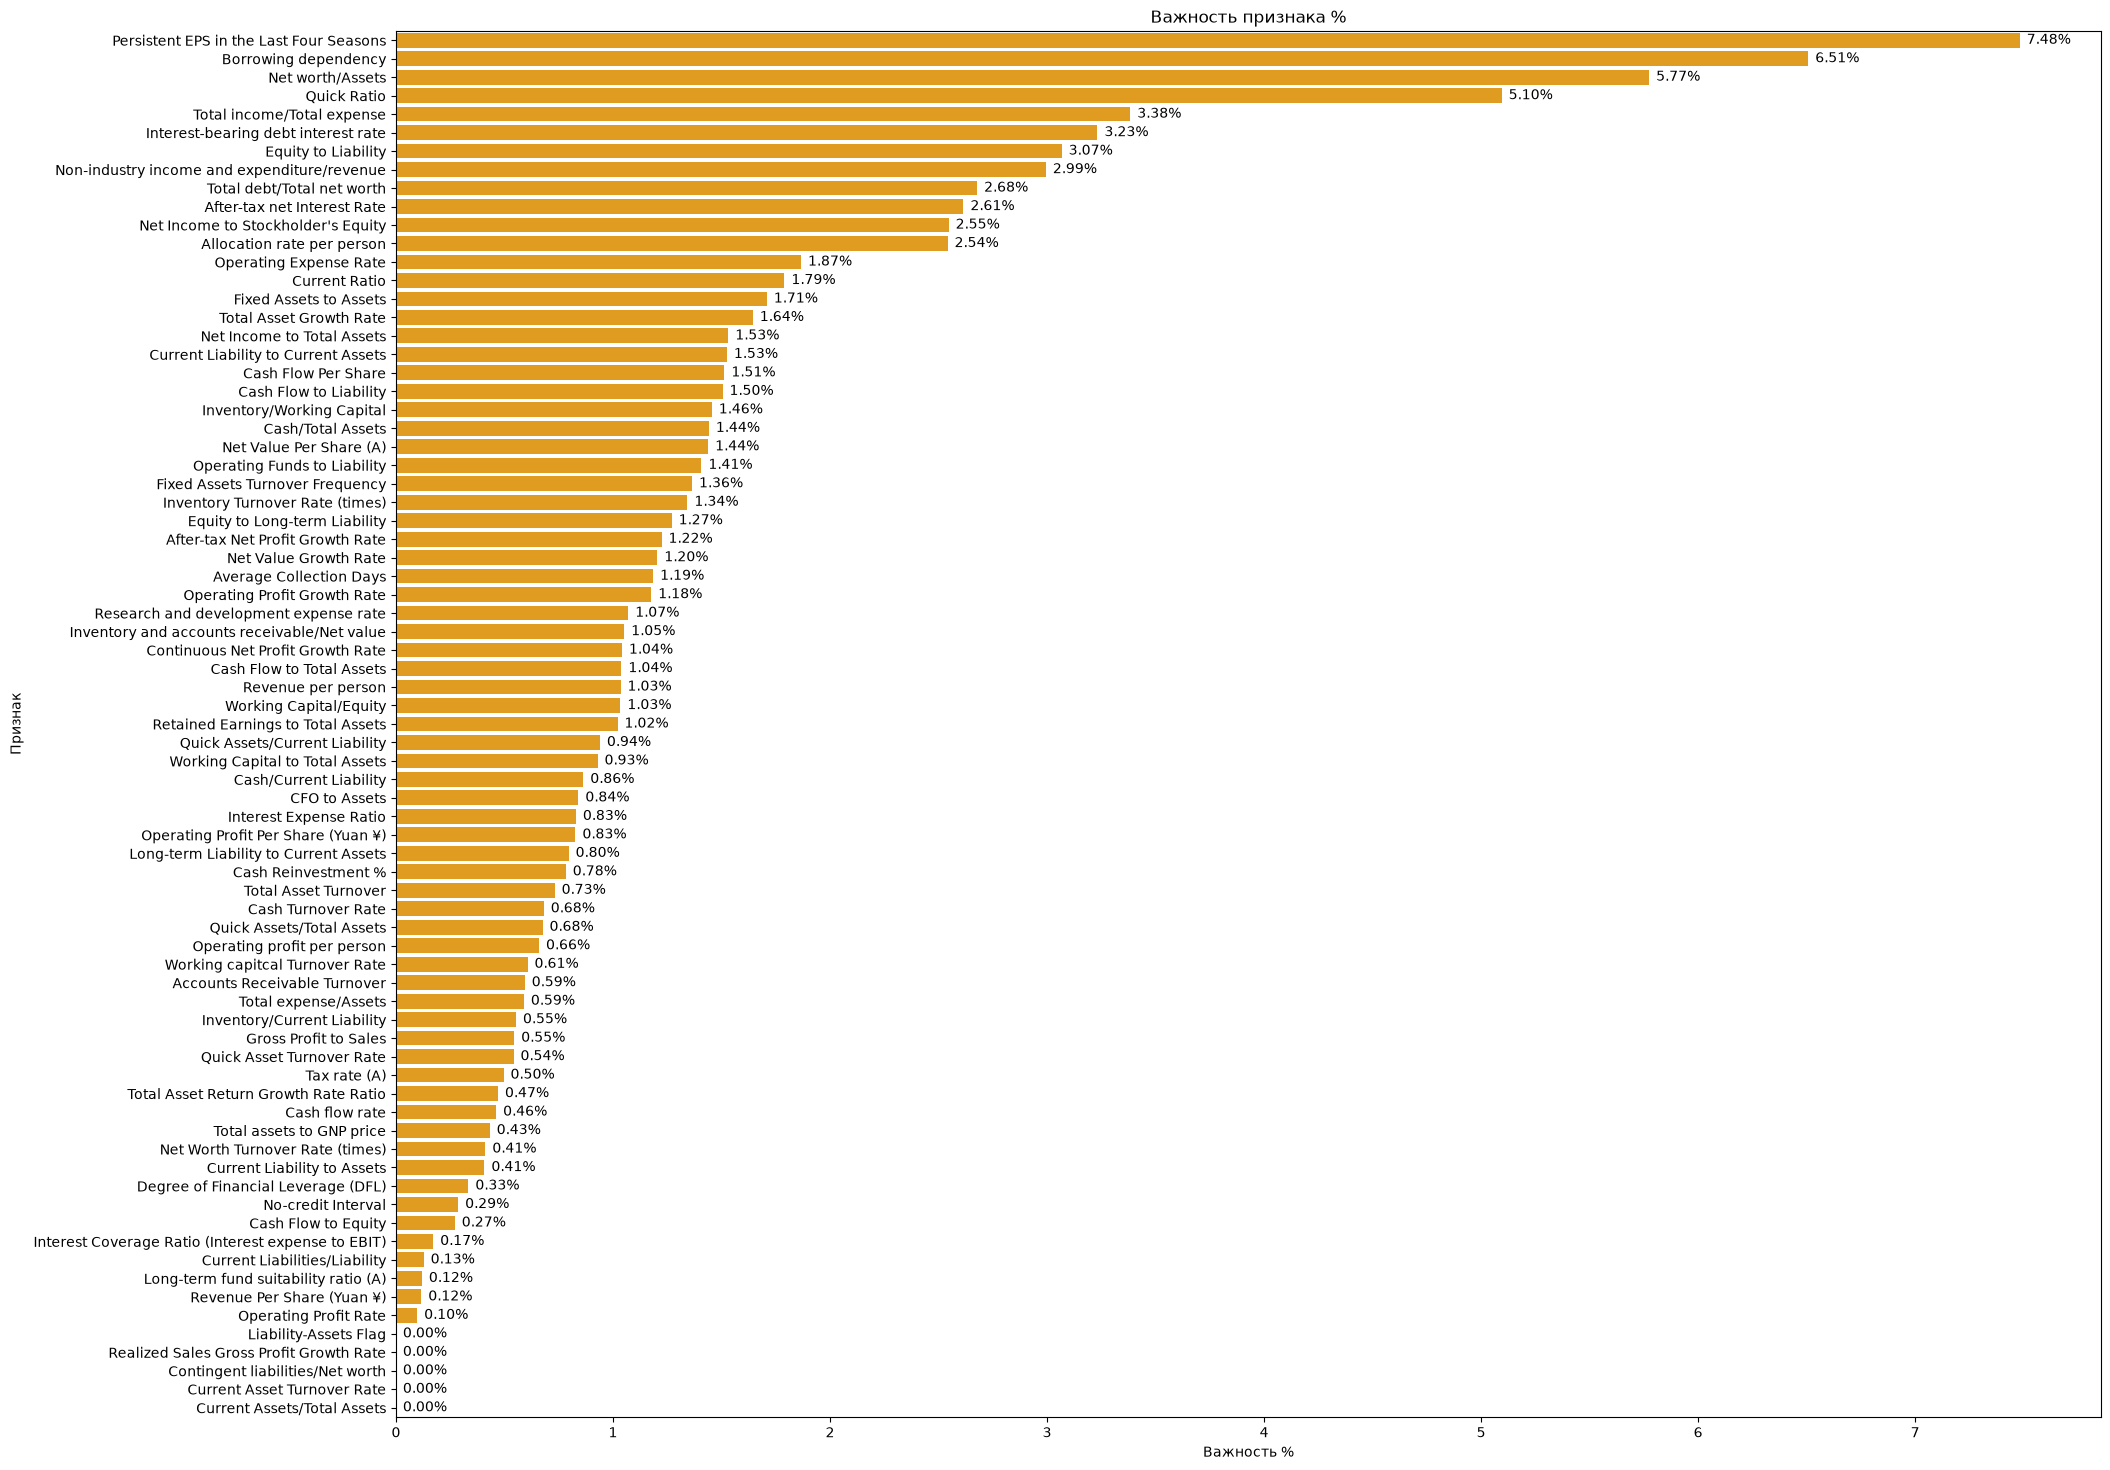

In [26]:
bankrupt_importance = pd.DataFrame({
    'Признак':feature_names,
    'Важность %':importance}).sort_values(by = 'Важность %', ascending = False)
bankrupt_importance

plt.figure(figsize=(22, 18))
ax = sns.barplot(data = bankrupt_importance, x='Важность %', y='Признак', color='orange' )
ax.bar_label(ax.containers[0], fmt='%.2f%%', fontsize=10, padding = 5)
plt.title('Важность признака %')
plt.show()

Визуальный анализ показал, что наиболее важными признаками являются стабильная прибыль на акцию за последние четыре сезона (7,48%), зависимость от заемных средств (6,51%), соотношение чистой стоимости компании к активам (5,77%) и коэффициент быстрой ликвидности (5,10%). Суммарно на эти четыре признака приходится около 25% всей предсказательной силы модели.

In [27]:
# Необходимо для расчета ROC-AUC
y_probability = model.predict_proba(X_test)[:,1]

In [28]:
print(classification_report(y_test, y_predict, target_names=['Не банкрот (0)', 'Банкрот(1)']))

                precision    recall  f1-score   support

Не банкрот (0)       0.99      0.92      0.96      1320
    Банкрот(1)       0.25      0.77      0.38        44

      accuracy                           0.92      1364
     macro avg       0.62      0.85      0.67      1364
  weighted avg       0.97      0.92      0.94      1364



In [29]:
# Подбор порога для валидационных клиентов
val_proba = model.predict_proba(X_val)[:,1]
prec, rec, thr =  precision_recall_curve(y_val, val_proba) # считаем множество линий

In [30]:
f1 = 2 * prec * rec / (prec + rec + 1e-9) #+ 1e-9 - для защиты от деления на ноль

In [31]:
best_thr = thr[f1[:-1].argmax()] # Выбираем лучшую оценку
y_pred_new = (y_probability >= best_thr).astype(int)

In [32]:
print(best_thr)

0.7908187846507412


In [33]:
print(classification_report(y_test, y_pred_new, target_names=['Не банкрот (0)', 'Банкрот(1)']))

                precision    recall  f1-score   support

Не банкрот (0)       0.98      0.97      0.98      1320
    Банкрот(1)       0.38      0.55      0.45        44

      accuracy                           0.96      1364
     macro avg       0.68      0.76      0.71      1364
  weighted avg       0.97      0.96      0.96      1364



In [34]:
# Расчет ROC-AUC
roc_auc = roc_auc_score(y_test, y_probability)
# PR-AUC (Area Under the Precision-Recall Curve)
pr_auc = average_precision_score(y_test, y_probability)
print(f'ROC-AUC: {roc_auc}')
print(f'PR-AUC: {pr_auc}')

ROC-AUC: 0.9384469696969697
PR-AUC: 0.46463883309048315


0.9384469696969697 - модель хорошо отделяет рискованные компании от надежных, даже если средний порог пока дает средние precision и recall

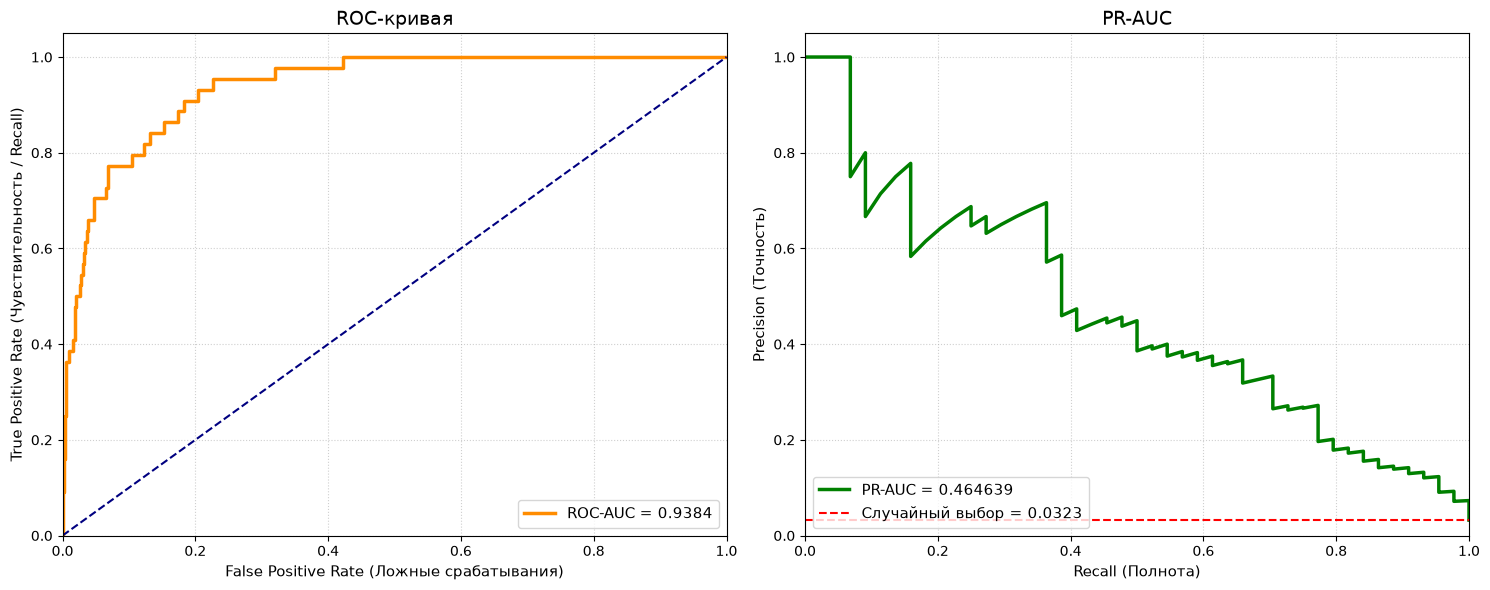

In [35]:
# Расчет точек для графиков
fpr, tpr, _ = roc_curve(y_test, y_probability) # False Positive Rate, True Positive Rate, пороги вероятности (thresholds)
precision, recall, _ = precision_recall_curve(y_test, y_probability) # один из классов встречается очень редко

# Создание сетки 
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))


# График: ROC-кривая
ax1.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2.5, # толщина линии
    label=f'ROC-AUC = {roc_auc:.4f}'
)
ax1.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate (Ложные срабатывания)', fontsize =11)
ax1.set_ylabel('True Positive Rate (Чувствительность / Recall)', fontsize =11)
ax1.set_title('ROC-кривая', fontsize =14)
ax1.legend(loc='lower right', fontsize =11)
ax1.grid(True, linestyle=':', alpha=0.6)

# График: PR-кривая
ax2.plot(
    recall,
    precision,
    color='green',
    lw=2.5, # толщина линии
    label=f'PR-AUC = {pr_auc:4f}'
)

# Линия случайного классификатора для PR зависит от баланса класса
# Доля единиц в y_test
baseline = sum(y_test)/len(y_test)
ax2.plot([0, 1], [baseline, baseline], color='red', lw=1.5, linestyle='--', label=f'Случайный выбор = {baseline:.4f}')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('Recall (Полнота)', fontsize =11)
ax2.set_ylabel('Precision (Точность)', fontsize =11)
ax2.set_title('PR-AUC', fontsize =14)
ax2.legend(loc='lower left', fontsize =11)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Вывод: в данной задаче наблюдается сильный дисбаланс классов (редкие целевые события).
ROC-AUC составляет 0.938, метрика оптимистична, но при явном дисбалансе лучше ориентироваться на PR-AUC.
PR-AUC составляет 0.465 при заданной доле целевого класса (доля 0,029: 200 банкротов на 6819 наблюдений). Precision составляет 0.38. F1-score составляет 0.45. Recall составляет 0.55, следовательно, модель пропускает 45% банкротов. 